In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(context = 'notebook',
              style = 'darkgrid',
              palette = 'deep',
              font = 'sans-serif',
              font_scale = 1,
              color_codes = True,
              rc = None)

from tqdm import tqdm

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Graph import

In [4]:
def parse_network_data(file_path):
    """
    Parse the mixed-format network data file into a pandas DataFrame.

    Args:
        file_path (str): Path to the input file.

    Returns:
        pd.DataFrame: A DataFrame with columns ['Source', 'Target', 'Weight', 'Timestamp'].
    """
    def parse_mixed_format(row):
        parts = row.strip().split('\t')
        if len(parts) >= 3:
            last_part = parts[-1].split()  # Split the last part to extract the timestamp
            if len(last_part) == 2:
                parts[-1], timestamp = last_part  # Adjust the last column and extract the timestamp
                return parts + [timestamp]
        return None

    # Read the raw content and parse the rows
    with open(file_path, 'r') as file:
        raw_content = file.readlines()

    parsed_data = [
        parse_mixed_format(line)
        for line in raw_content
        if not line.startswith('%') and parse_mixed_format(line) is not None
    ]

    # Create a DataFrame and convert columns to appropriate types
    columns = ['Source', 'Target', 'Weight', 'Timestamp']
    dataframe = pd.DataFrame(parsed_data, columns=columns).astype(int)

    dataframe['Datetime'] = pd.to_datetime(dataframe['Timestamp'], unit='s')

    return dataframe

def create_cumulative_graph(dataframe, timestamp_index):
    """
    Create a cumulative NetworkX graph up to a given timestamp index.

    Args:
        dataframe (pd.DataFrame): A DataFrame containing network data with 'Timestamp'.
        timestamp_index (int): Index (0-based) corresponding to the desired timestamp.

    Returns:
        networkx.Graph: A cumulative graph up to the specified timestamp.
    """
    # Ensure the DataFrame is sorted by timestamp
    dataframe = dataframe.sort_values('Timestamp')

    # Get unique timestamps and validate the index
    unique_timestamps = sorted(dataframe['Timestamp'].unique())
    if timestamp_index < 0 or timestamp_index >= len(unique_timestamps):
        raise ValueError(f"Timestamp index must be between 0 and {len(unique_timestamps) - 1}.")

    # Filter the data up to the specified timestamp
    cutoff_timestamp = unique_timestamps[timestamp_index]
    cumulative_data = dataframe[dataframe['Timestamp'] <= cutoff_timestamp]

    # Create the graph
    G = nx.Graph()
    for _, row in cumulative_data.iterrows():
        if row['Source'] != row['Target']:  # Ignore self-loops
            G.add_edge(row['Source'], row['Target'])

    return G

In [5]:
network_pandas = parse_network_data('test_networks/out.dblp-cite')

In [6]:
network_pandas

,Source,Target,Weight,Timestamp,Datetime
0,1,2,1,820454461,1996-01-01 00:01:01
1,1,3,1,820454461,1996-01-01 00:01:01
2,10001,10002,1,915148861,1999-01-01 00:01:01
3,10001,10003,1,915148861,1999-01-01 00:01:01
4,10001,10004,1,915148861,1999-01-01 00:01:01
...,...,...,...,...,...
49754,9996,8019,1,725846461,1993-01-01 00:01:01
49755,9996,880,1,725846461,1993-01-01 00:01:01
49756,9996,954,1,725846461,1993-01-01 00:01:01
49757,9996,9993,1,725846461,1993-01-01 00:01:01


## Explore the network over time

In [7]:
len(network_pandas['Timestamp'].unique())

30

In [8]:
nodes = []
edges = []
avg_degrees = []
for i in tqdm(range(len(network_pandas['Timestamp'].unique()))):
    g = create_cumulative_graph(network_pandas, i)
    node = g.number_of_nodes()
    edge = g.number_of_edges()
    avg_degree = 2 * edge / node
    nodes.append(node)
    edges.append(edge)
    avg_degrees.append(avg_degree)

100%|██████████| 30/30 [00:24<00:00,  1.21it/s]


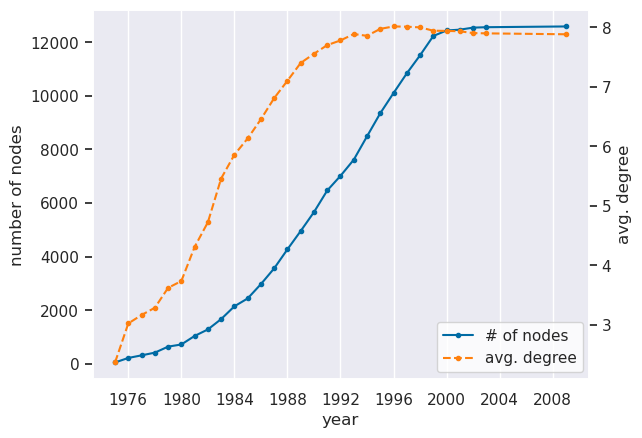

In [9]:
times = sorted(network_pandas['Datetime'].unique())
fig, ax = plt.subplots()
ax.plot(times,nodes,color='#006BA4',label='# of nodes',marker='.')
ax.set_xlabel('year')
ax.set_ylabel('number of nodes')
ax2 = ax.twinx()
ax2.plot(times,avg_degrees,color='#FF800E',label='avg. degree',marker='.',linestyle='--')
ax2.set_ylabel('avg. degree')
ax.grid(False)
ax2.grid(False)
fig.legend(loc=(0.68,0.15),facecolor='white')
ax.xaxis.grid(True)
plt.savefig('./figures/dblp_cite_growth_over_time.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

In [10]:
G_start = create_cumulative_graph(network_pandas, 2)

In [11]:
G = G_start

In [12]:
len(G)

314

In [13]:
2 * G.number_of_edges() / G.number_of_nodes()

3.1656050955414012

In [51]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/(np.log(m_size)))+1)

2  k_max:  9
3  k_max:  6
5  k_max:  4
6  k_max:  4
7  k_max:  3


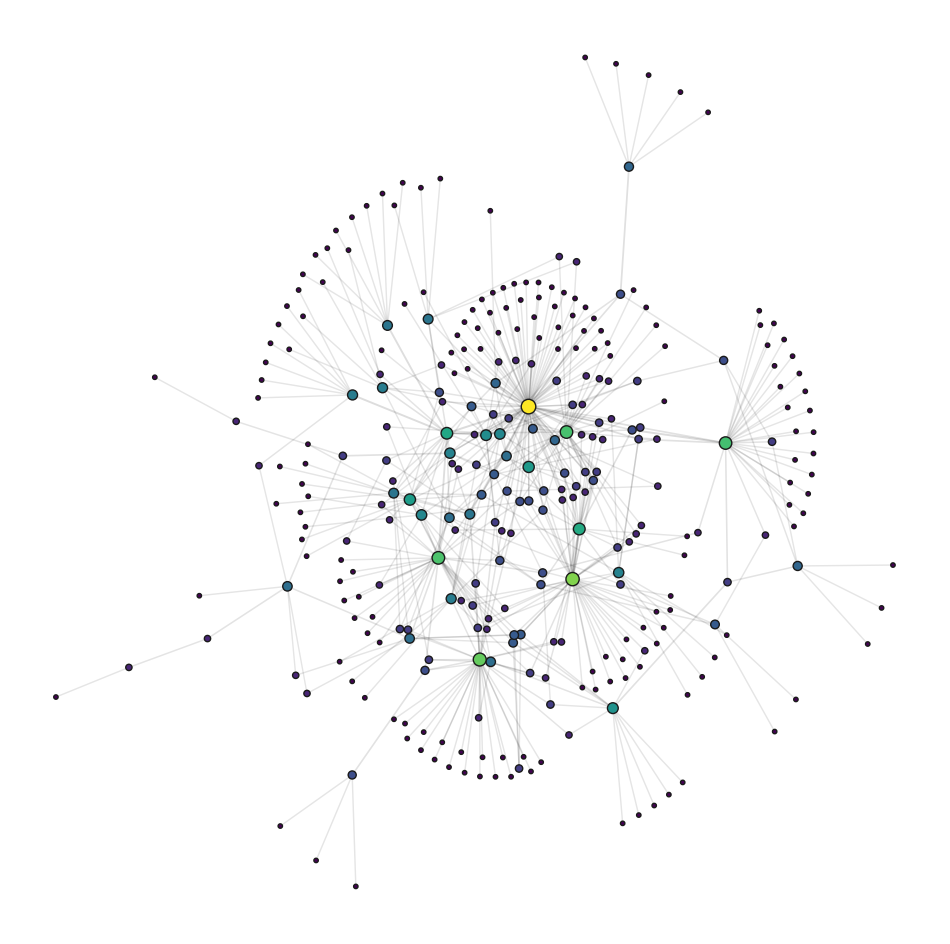

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm

# Keep only the largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_largest = G.subgraph(largest_cc).copy()

# Sort nodes by degree (ascending), so high-degree nodes are processed last
sorted_nodes = sorted(G_largest.nodes(), key=lambda x: G_largest.degree[x], reverse=True)

# Relabel the graph nodes to ensure sorted order is reflected
mapping = {node: i for i, node in enumerate(sorted_nodes)}
G_largest = nx.relabel_nodes(G_largest, mapping)

# Recalculate node degrees (now sorted)
degree = dict(G_largest.degree())
nx.set_node_attributes(G_largest, degree, 'degree')

# Node size based on degree (logarithmic scaling)
degrees = np.array(list(degree.values()))
degrees += 1  # Avoid log(0) by shifting values
node_sizes = 10 + 100 * (np.log(degrees) - np.log(degrees.min())) / (
    np.log(degrees.max()) - np.log(degrees.min())
)

# Node color based on degree (logarithmic scaling)
cmap = plt.cm.viridis
node_colors = cmap((np.log(degrees) - np.log(degrees.min())) / (np.log(degrees.max()) - np.log(degrees.min())))

# Calculate edge betweenness centrality (for edge width and alpha)
edge_betweenness = nx.edge_betweenness_centrality(G_largest)
edge_widths = [1 + 7 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale edge widths for visibility
edge_alphas = [0.1 + 0.6 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale alpha from 0.1 to 1.0

# Positioning nodes using a force-directed layout
pos = nx.kamada_kawai_layout(G_largest)

# Plot the network
plt.figure(figsize=(12, 12))
# Draw edges with scaled widths and alphas
for edge, width, alpha in zip(G_largest.edges(), edge_widths, edge_alphas):
    nx.draw_networkx_edges(
        G_largest,
        pos,
        edgelist=[edge],
        width=width,
        alpha=alpha,
        edge_color="black",
    )

# Draw nodes with size and color mapped to attributes
nx.draw_networkx_nodes(
    G_largest,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=cmap,
    edgecolors='k',  # Add a border to nodes for clarity
)

# Remove labels and title for a cleaner plot
plt.gca().set_facecolor("black")

# Hide axes for cleaner visualization
plt.axis('off')
plt.savefig('./figures/dblp_cite_314_nodes_layout.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

# Init Fitter

In [14]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.019879
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.426570


In [15]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 497},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 8774},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 63},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 168969},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 21757},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 4015},
 {'name': 'four_loop

# Grid Search

In [32]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,4]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,3]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'energy'
)

[I 2025-02-20 08:30:19,305] A new study created in memory with name: no-name-4dee8fc4-fbb9-4eef-afa8-72ce8ea705ca


Grid Search requires 8 trials...


[I 2025-02-20 08:30:27,020] Trial 0 finished with value: 13.31110658136801 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 13.31110658136801.
[I 2025-02-20 08:30:35,455] Trial 1 finished with value: 13.058146344729256 and parameters: {'m': 2, 'k': 3}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:30:41,995] Trial 2 finished with value: 13.075387391634177 and parameters: {'m': 2, 'k': 2}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:30:50,971] Trial 3 finished with value: 14.024507016098559 and parameters: {'m': 2, 'k': 8}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:30:57,998] Trial 4 finished with value: 13.14036703606088 and parameters: {'m': 2, 'k': 4}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:31:05,339] Trial 5 finished with value: 13.22497907035558 and parameters: {'m': 2, 'k': 1}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:31:11,592] Trial 6 finished with value:

Grid Search requires 5 trials...


[I 2025-02-20 08:31:36,655] Trial 0 finished with value: 12.48983444990796 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 12.48983444990796.
[I 2025-02-20 08:31:52,685] Trial 1 finished with value: 11.794394789017925 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 11.794394789017925.
[I 2025-02-20 08:32:07,451] Trial 2 finished with value: 11.270924328832313 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 11.270924328832313.
[I 2025-02-20 08:32:25,237] Trial 3 finished with value: 12.576406377924764 and parameters: {'m': 3, 'k': 4}. Best is trial 2 with value: 11.270924328832313.
[I 2025-02-20 08:32:50,331] Trial 4 finished with value: 12.42866342131719 and parameters: {'m': 3, 'k': 5}. Best is trial 2 with value: 11.270924328832313.
[I 2025-02-20 08:32:50,332] A new study created in memory with name: no-name-fa67979b-c12e-4e3f-b72c-bb057d8385ce


Grid Search requires 3 trials...


... (2 outputs left out)

[I 2025-02-20 08:36:17,658] Trial 0 finished with value: 11.83875766146727 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 11.83875766146727.
[I 2025-02-20 08:37:17,584] Trial 1 finished with value: 11.15688609994119 and parameters: {'m': 6, 'k': 2}. Best is trial 1 with value: 11.15688609994119.
[I 2025-02-20 08:37:59,925] Trial 2 finished with value: 11.985865241632288 and parameters: {'m': 6, 'k': 1}. Best is trial 1 with value: 11.15688609994119.
[I 2025-02-20 08:37:59,926] A new study created in memory with name: no-name-7644e901-afcc-4800-93f6-2447a653dde1


Grid Search requires 2 trials...


[I 2025-02-20 08:39:27,078] Trial 0 finished with value: 11.164790611462033 and parameters: {'m': 7, 'k': 2}. Best is trial 0 with value: 11.164790611462033.
[I 2025-02-20 08:40:08,370] Trial 1 finished with value: 11.224578249145218 and parameters: {'m': 7, 'k': 1}. Best is trial 0 with value: 11.164790611462033.


Best parameters:  {'m': 5, 'k': 1}
Best energy:  11.08423232349914
Best KL-divergence:  0.09143908117202902
Best KLD augumented energy: 5.289236243580942
Best P matrix:
 [[1.45437535e-06 1.01942276e-02 8.86047729e-02 1.44301792e-01
  3.18238289e-01]
 [1.01942276e-02 9.92276823e-02 7.46967104e-02 1.72391217e-01
  3.55732320e-01]
 [8.86047729e-02 7.46967104e-02 1.44306436e-01 1.66100763e-01
  2.09350946e-01]
 [1.44301792e-01 1.72391217e-01 1.66100763e-01 3.58314573e-01
  2.79069194e-01]
 [3.18238289e-01 3.55732320e-01 2.09350946e-01 2.79069194e-01
  2.50826146e-01]]
Best l vector:
 [0.84910202 0.11933044 0.02913221 0.00209109 0.00170323]


Energy: 11.14243606652993
KL-divergence: 0.12826468352322085
KLD augumented energy: 5.894185390446013


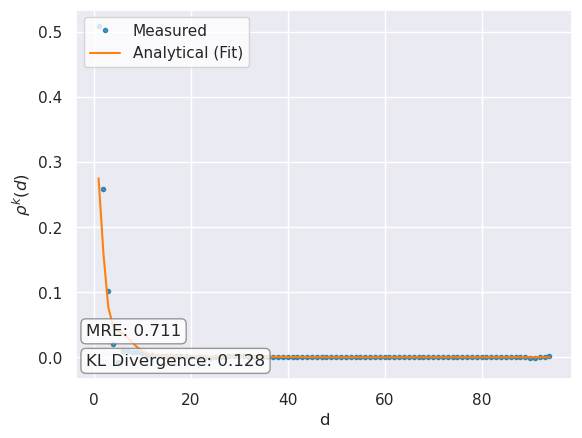

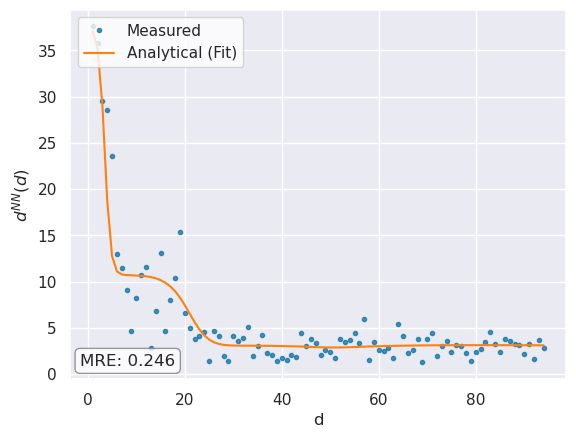

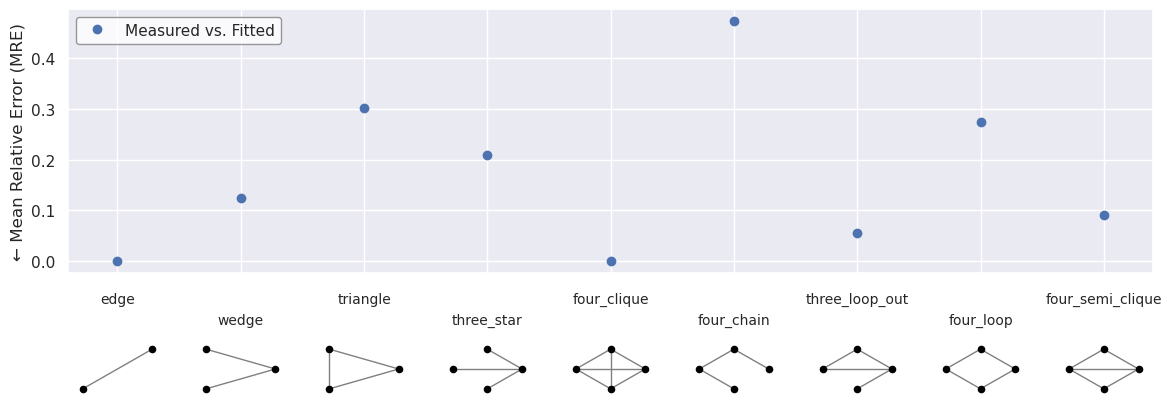

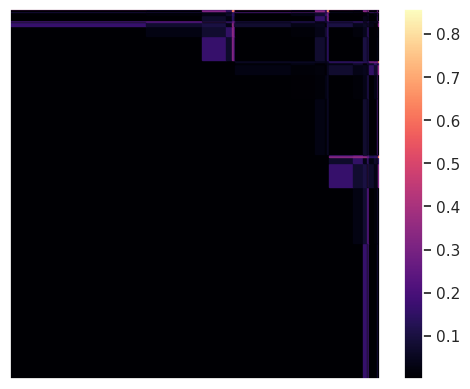

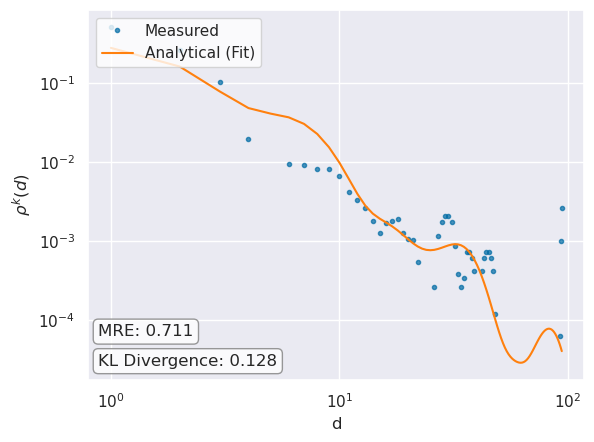

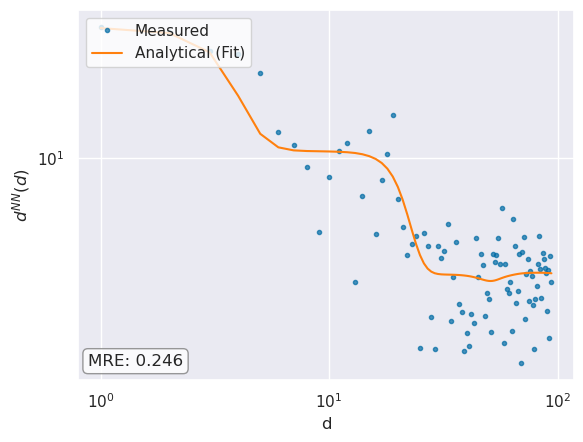

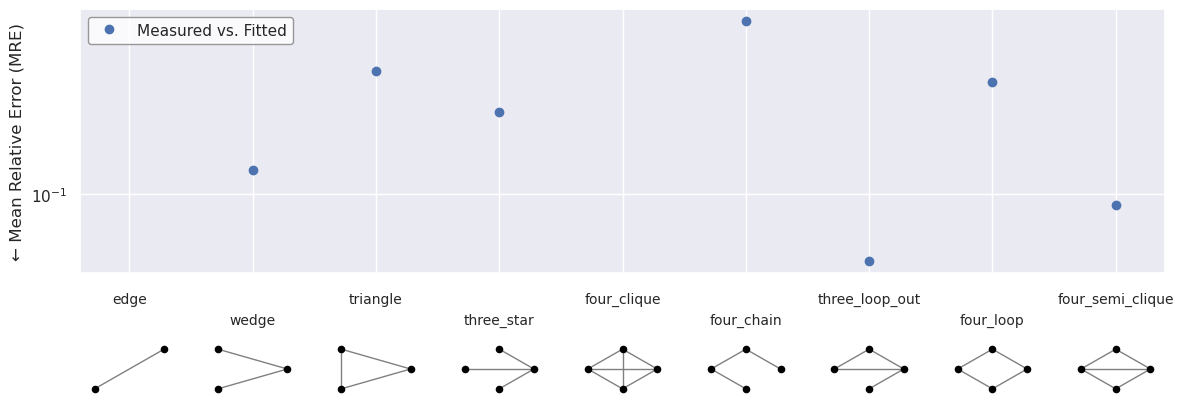

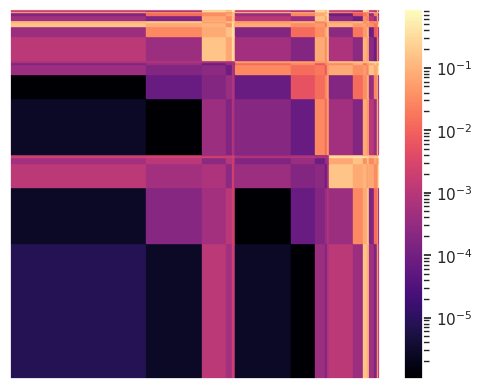

In [36]:
mfnf.find_P_l(7,2, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
)

In [ ]:
# We choose 7-2, as the 'best' measures result in k+1-s, that corresponds to networks with 100k nodes, 
# which is too large for this dataset.

# Bootstrap Stability

In [39]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'lowest'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [44:11<00:00, 88.37s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.265025
Energy = 10.86 (10.86, 11.56)
l = [0.73 (0.47, 0.86), 0.09 (0.05, 0.38), 0.09 (0.02, 0.11), 0.05 (0.01, 0.10), 0.03 (0.00, 0.05), 0.00 (0.00, 0.03), 0.00 (0.00, 0.03)]
P = [
[0.00 (0.00, 0.05), 0.00 (0.00, 0.38), 0.31 (0.00, 0.64), 0.33 (0.00, 0.89), 0.12 (0.00, 0.99), 0.95 (0.05, 0.98), 0.43 (0.01, 0.97)],

[0.00 (0.00, 0.38), 0.25 (0.00, 0.81), 0.00 (0.01, 0.55), 0.63 (0.02, 0.73), 0.40 (0.05, 0.95), 0.89 (0.00, 0.98), 0.65 (0.00, 0.99)],

[0.31 (0.00, 0.64), 0.00 (0.01, 0.55), 0.75 (0.06, 0.90), 0.01 (0.01, 0.99), 0.27 (0.00, 0.85), 0.34 (0.01, 0.99), 0.13 (0.02, 0.88)],

[0.33 (0.00, 0.89), 0.63 (0.02, 0.73), 0.01 (0.01, 0.99), 0.68 (0.02, 0.98), 0.42 (0.04, 0.92), 0.75 (0.04, 0.91), 0.36 (0.01, 0.90)],

[0.12 (0.00, 0.99), 0.40 (0.05, 0.95), 0.27 (0.00, 0.85), 0.42 (0.04, 0.92), 0.35 (0.01, 0.99), 0.90 (0.00, 0.94), 0.47 (0.04, 0.90)],

[0.95 (0.05, 0.98), 0.89 (0.00, 0.98), 0.34 (0.01, 0.99), 0.75 (0.04, 0.91), 0.90 (0.00, 0.94), 0.88 (0.0

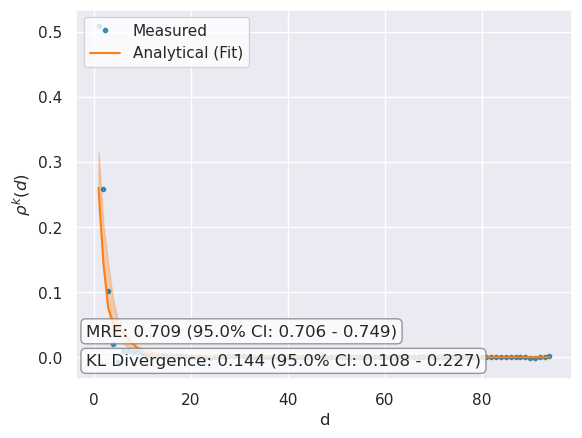

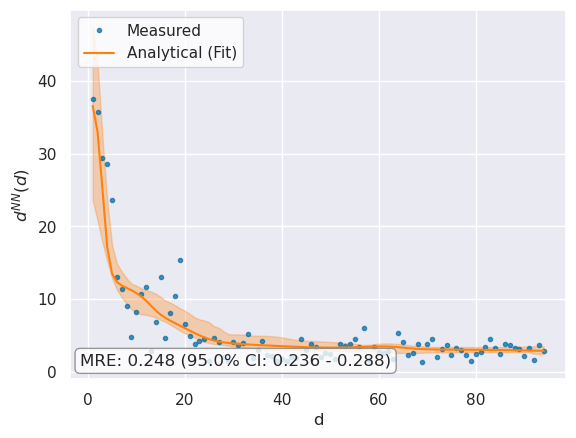

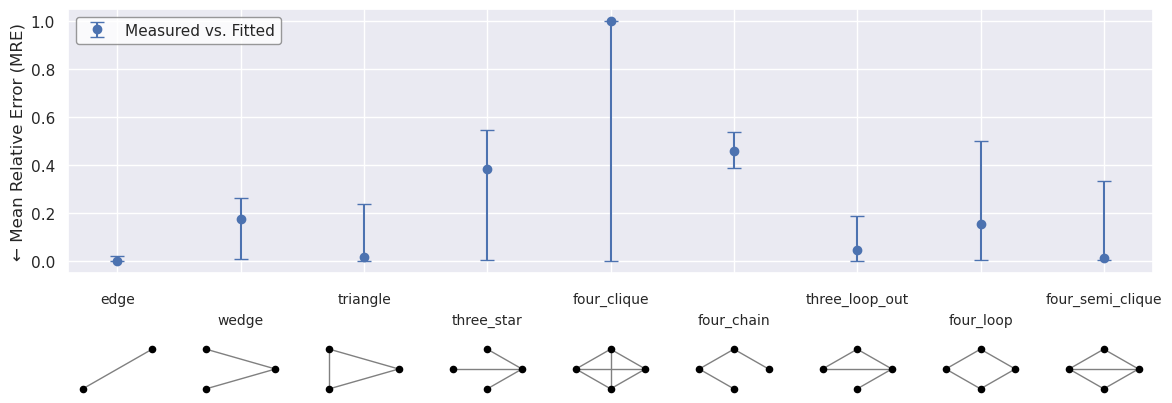

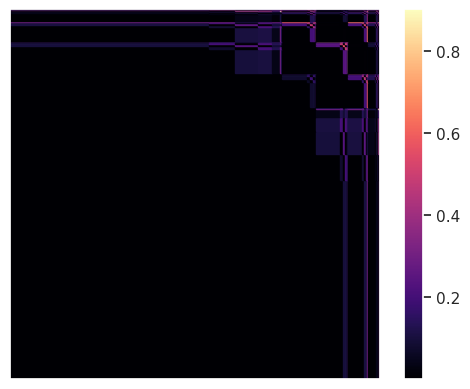

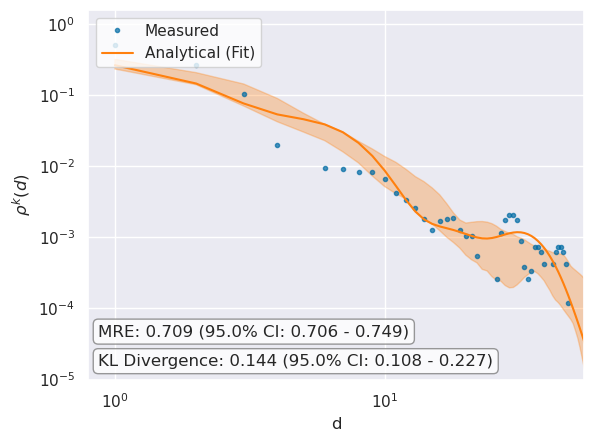

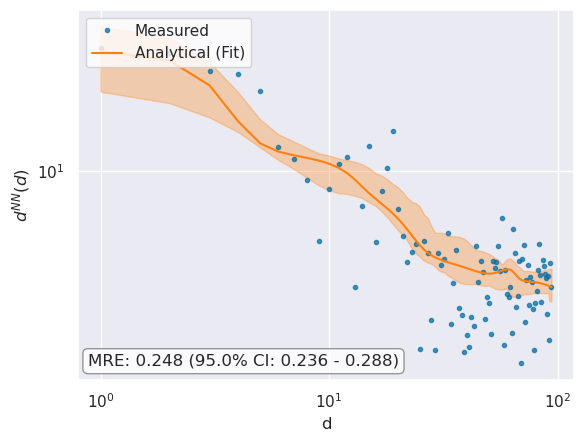

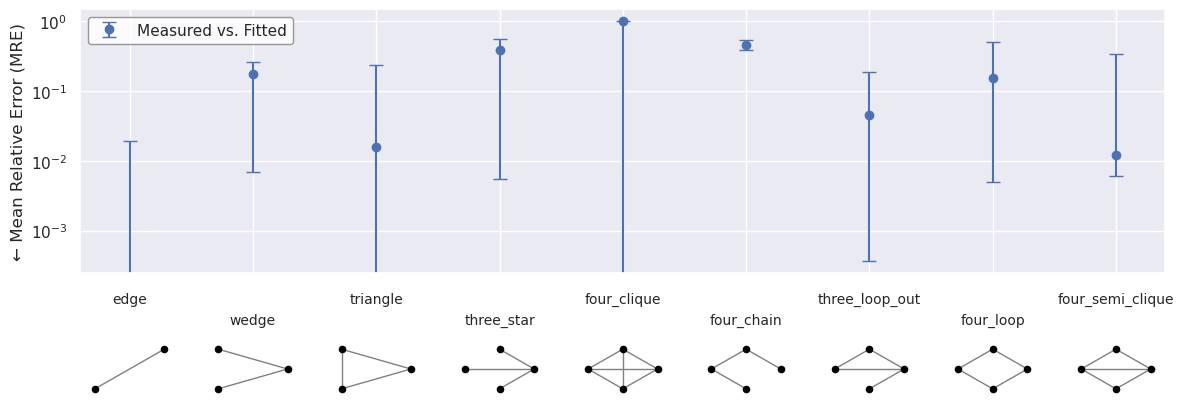

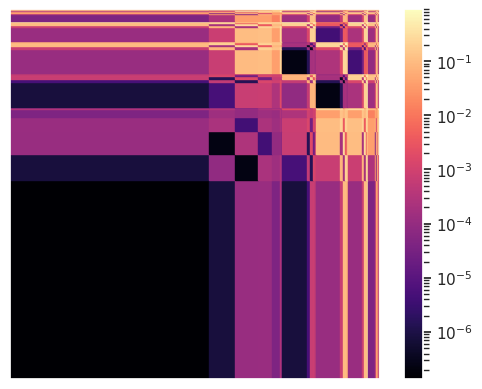

In [64]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/dblp_cite_300_nodes_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = (0,55),
    ylim = (1e-5,0),
    filename = "figures/dblp_cite_300_nodes_log_plot.pdf"
)

In [63]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 497,
  'expected_count': 497,
  'MRE': 0.0,
  'expected_count_ci_low': 489.0,
  'expected_count_ci_high': 503.525,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.01901398548772948},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 8774,
  'expected_count': 7255,
  'MRE': 0.17312514246637795,
  'expected_count_ci_low': 6465.275,
  'expected_count_ci_high': 8865.0,
  'MRE_ci_low': 0.006850500523839164,
  'MRE_ci_high': 0.26313255071803054},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 63,
  'expected_count': 62,
  'MRE': 0.015873015873015872,
  'expected_count_ci_low': 48.0,
  'expected_count_ci_high': 69.57499999999997,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.23809523809523808},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 

In [62]:
import pickle
with open('./test_networks/dblp_cite_300_nodes_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Scaling the network

In [41]:
def recommend_N_for_k_range(P, l, k, avg_degree, k_limit):
    s2 = np.sum(np.outer(l, l) * P)
    recommendations = {}
    for new_k in range(k + 1, k_limit + 1):
        # Calculate the required network size N
        edge_proba_k = s2**new_k
        recommended_N = int(2 * avg_degree / edge_proba_k + 1)
        recommendations[new_k] = recommended_N
    
    return recommendations

In [42]:
recommend_N_for_k_range(mfnf.P, mfnf.l, mfnf.k, 3 * G.number_of_edges() / G.number_of_nodes(), 4)

{3: 9334, 4: 92795}

In [43]:
print(len(create_cumulative_graph(network_pandas, 20)))

9351


In [44]:
G_20 = create_cumulative_graph(network_pandas, 20)

In [45]:
mfnf_no_fit = MultifractalNetworkFitter(
    G_20,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:04.430211
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:11:05.896281


In [46]:
mfnf_no_fit.save_motifs('./test_networks/dblp_cite_9351_nodes_motifs.pkl')

In [47]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 37292},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1505431},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 32310},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 125817748},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 16149},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 36489445},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 6149985},

In [52]:
from copy import deepcopy

In [53]:
mfnf_no_fit.P = deepcopy(mfnf.P)
mfnf_no_fit.l = deepcopy(mfnf.l)
mfnf_no_fit.k = 3
mfnf_no_fit.resampled_best_candidates = deepcopy(mfnf.resampled_best_candidates)
mfnf_no_fit.resampled_best_energies = deepcopy(mfnf.resampled_best_energies)
mfnf_no_fit.bootstrap = True
mfnf_no_fit._calculate_bootstrap_metrics(ci = 0.95, medoid = 'lowest')

Energy = 10.86 (10.86, 11.56)
l = [0.73 (0.47, 0.86), 0.09 (0.05, 0.38), 0.09 (0.02, 0.11), 0.05 (0.01, 0.10), 0.03 (0.00, 0.05), 0.00 (0.00, 0.03), 0.00 (0.00, 0.03)]
P = [
[0.00 (0.00, 0.05), 0.00 (0.00, 0.38), 0.31 (0.00, 0.64), 0.33 (0.00, 0.89), 0.12 (0.00, 0.99), 0.95 (0.05, 0.98), 0.43 (0.01, 0.97)],

[0.00 (0.00, 0.38), 0.25 (0.00, 0.81), 0.00 (0.01, 0.55), 0.63 (0.02, 0.73), 0.40 (0.05, 0.95), 0.89 (0.00, 0.98), 0.65 (0.00, 0.99)],

[0.31 (0.00, 0.64), 0.00 (0.01, 0.55), 0.75 (0.06, 0.90), 0.01 (0.01, 0.99), 0.27 (0.00, 0.85), 0.34 (0.01, 0.99), 0.13 (0.02, 0.88)],

[0.33 (0.00, 0.89), 0.63 (0.02, 0.73), 0.01 (0.01, 0.99), 0.68 (0.02, 0.98), 0.42 (0.04, 0.92), 0.75 (0.04, 0.91), 0.36 (0.01, 0.90)],

[0.12 (0.00, 0.99), 0.40 (0.05, 0.95), 0.27 (0.00, 0.85), 0.42 (0.04, 0.92), 0.35 (0.01, 0.99), 0.90 (0.00, 0.94), 0.47 (0.04, 0.90)],

[0.95 (0.05, 0.98), 0.89 (0.00, 0.98), 0.34 (0.01, 0.99), 0.75 (0.04, 0.91), 0.90 (0.00, 0.94), 0.88 (0.02, 0.99), 0.58 (0.01, 0.98)],

[0.43 (0.0

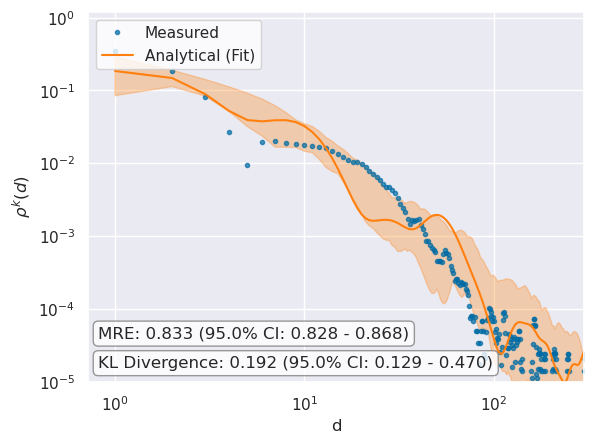

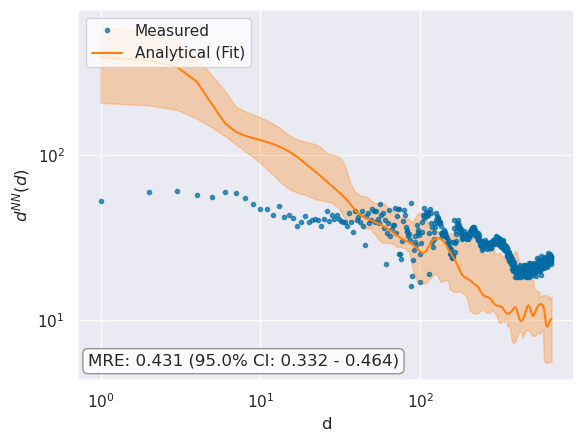

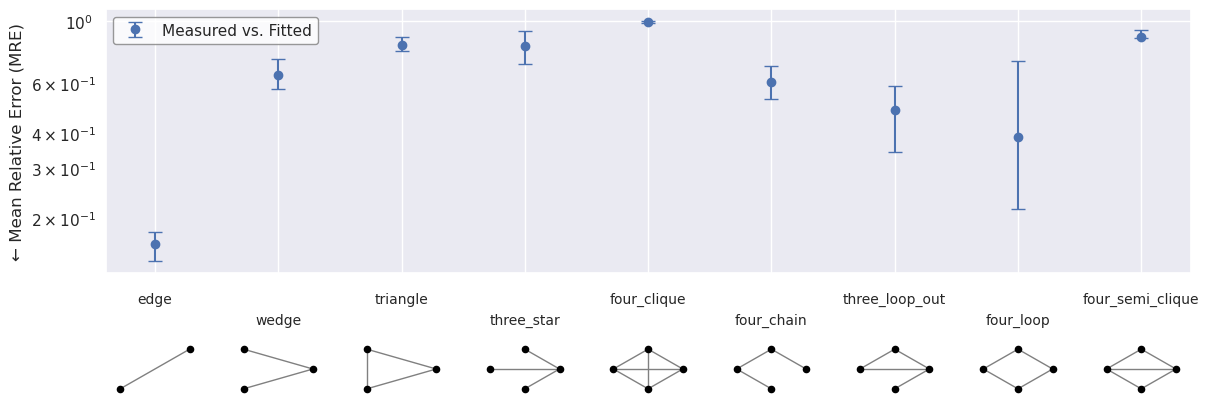

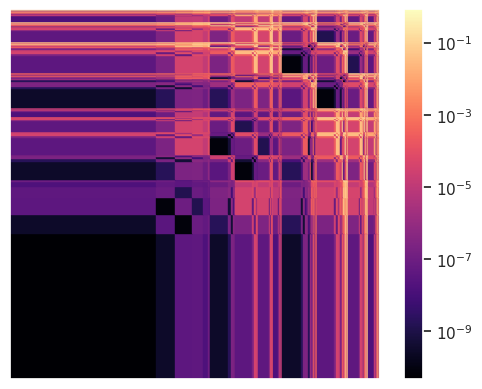

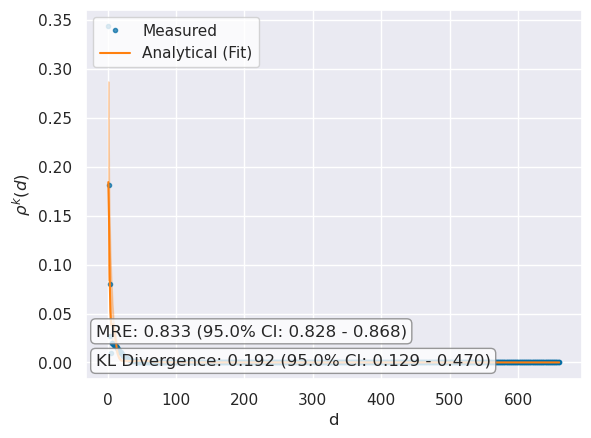

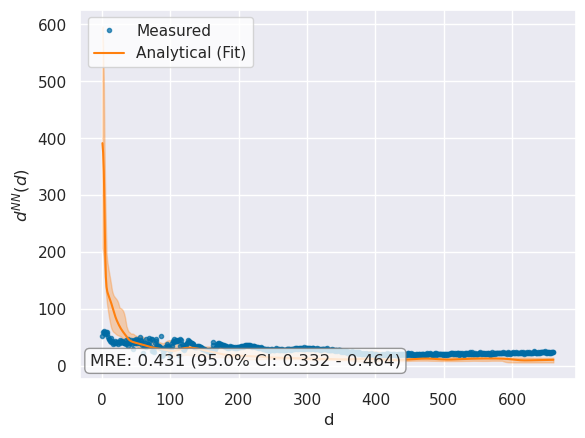

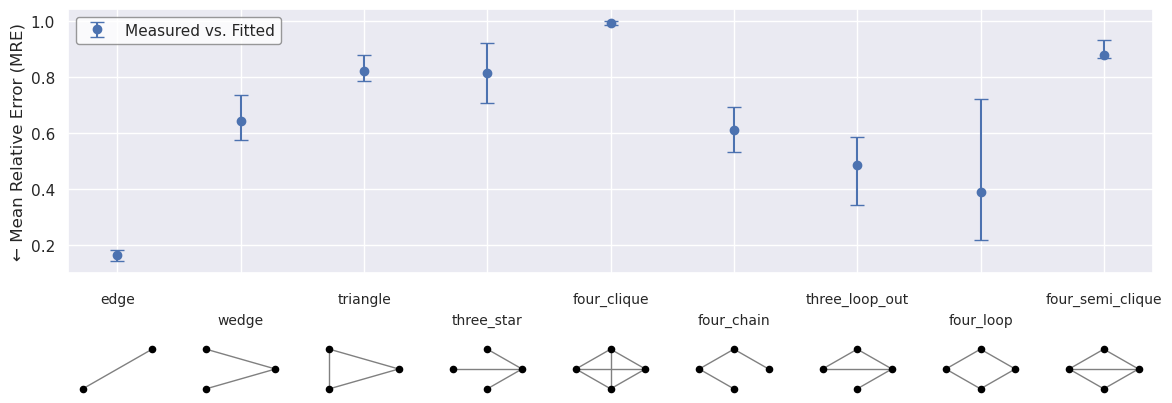

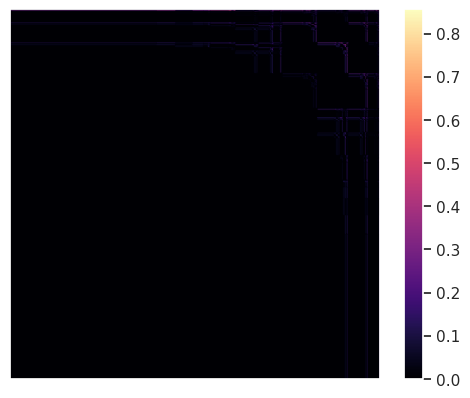

In [54]:
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = (0,300),
    ylim = (1e-5,0),
    filename = "figures/dblp_cite_9300_nodes_log_plot.pdf"
)

mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/dblp_cite_9300_nodes_plot.pdf"
)

In [57]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 37292,
  'expected_count': 44481,
  'MRE': 0.1616195679053978,
  'expected_count_ci_low': 43422.0,
  'expected_count_ci_high': 45414.6,
  'MRE_ci_low': 0.14117267744461334,
  'MRE_ci_high': 0.17885432003723342},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1505431,
  'expected_count': 4207659,
  'MRE': 0.6422164914029392,
  'expected_count_ci_low': 3539342.025,
  'expected_count_ci_high': 5682538.0,
  'MRE_ci_low': 0.5746574818928379,
  'MRE_ci_high': 0.7350777064755221},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 32310,
  'expected_count': 5816,
  'MRE': 0.8199938099659548,
  'expected_count_ci_low': 3923.0,
  'expected_count_ci_high': 6949.349999999997,
  'MRE_ci_low': 0.78491643454039,
  'MRE_ci_high': 0.8785824822036521},
 {'name': 'three_star',
  'matr